# 06 · Customer activity and segments
Questions 23–31: who is active, who is going quiet, and whether a bad experience matters.

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data_loader import get_engine, query, PROJECT_ROOT
from src import analysis as an
an.set_style()
pd.set_option("display.float_format", "{:,.2f}".format); pd.set_option("display.max_columns", 30)
engine = get_engine()
o = an.sql_output

In [2]:
o('q23_activity_by_segment')

,segment,customers,avg_monthly_active_rate_pct,txns_per_active_month,value_per_active_month_kes,fees_per_active_month_kes
0,Premier,1839,83.80,9.00,"235,810.00",302.80
1,Salaried,6002,79.80,7.10,"48,670.00",155.50
2,SME,3632,79.00,11.80,"455,892.00",524.20
3,Mass Retail,11952,67.70,3.90,"12,436.00",72.20
4,Youth,6575,67.60,5.10,"10,742.00",70.00


activity_status,Active (last 30 days),At risk (30-89 days),Dormant (90+ days),Too new to assess
segment,,,,
Premier,77.70,4.10,10.70,7.60
Salaried,75.20,4.90,12.70,7.20
SME,71.80,4.20,16.20,7.80
Mass Retail,61.20,10.50,20.60,7.80
Youth,59.30,8.80,24.00,7.80


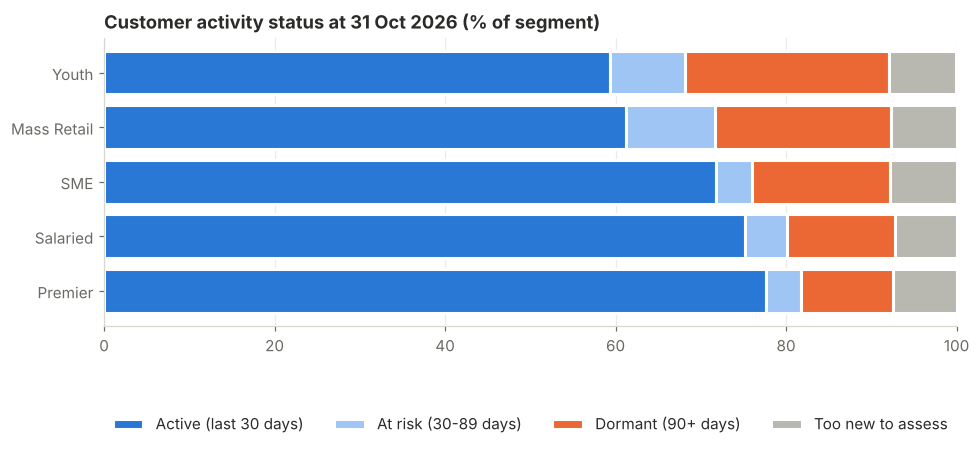

In [3]:
s = o('q24_activity_status').pivot(index='segment', columns='activity_status', values='share_of_segment_pct').fillna(0)
order = ['Active (last 30 days)', 'At risk (30-89 days)', 'Dormant (90+ days)', 'Too new to assess']
s = s[order].sort_values('Dormant (90+ days)')
fig, ax = plt.subplots(figsize=(10, 3.4)); left = np.zeros(len(s))
colors = [an.PRIMARY, '#9ec5f4', an.HIGHLIGHT, an.CONTEXT]
for col, colr in zip(order, colors):
    ax.barh(s.index, s[col], left=left, color=colr, label=col, edgecolor='white', linewidth=2); left += s[col].values
ax.set_xlim(0, 100); ax.set_title("Customer activity status at 31 Oct 2026 (% of segment)"); ax.legend(ncol=4, loc='lower center', bbox_to_anchor=(0.5, -0.42))
an.save(fig, "activity_status_by_segment"); s

About **19% of customers are dormant** (no successful transaction in 90 days), mostly Mass Retail and Youth. Premier, SME and Salaried customers are much more consistently active.

In [4]:
o('q25_dormancy_by_onboarding_channel')

,onboarding_channel,assessable_customers,dormant_pct,avg_channels_used
0,Agent,6705,21.20,4.49
1,Mobile App,7632,20.90,4.28
2,USSD,2337,19.60,4.53
3,Branch,11023,19.20,4.72


months_since_onboarding,0,1,2,3,4,5,6,7,8,9,10,11,12
active_pct,66.70,72.20,72.00,72.00,72.20,72.10,72.10,72.30,72.60,72.10,71.80,71.20,72.10


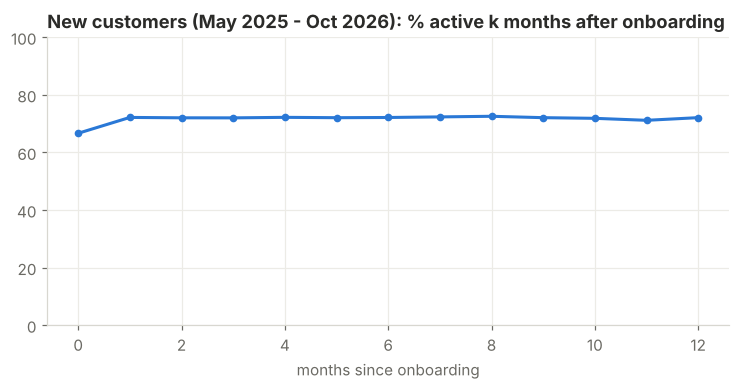

In [5]:
c = o('q26_new_customer_activation')
curve = c.groupby('months_since_onboarding').apply(lambda g: np.average(g.active_pct, weights=g.cohort_size)).rename('active_pct')
fig, ax = plt.subplots(figsize=(8, 3.4)); ax.plot(curve.index, curve.values, color=an.PRIMARY, marker='o', ms=4)
ax.set_title("New customers (May 2025 - Oct 2026): % active k months after onboarding"); ax.set_xlabel('months since onboarding'); ax.set_ylim(0, 100)
an.save(fig, "new_customer_activation"); curve.round(1).to_frame().T

New customers are less active in their onboarding month (they join part-way through it). From the following month about 72% are active each month, the same rate as the established base.

,activity_band,operational_failures_in_month,customer_months,active_next_month_pct,inactive_next_month_pct
0,a) 1-3 attempts,a) none,107478,83.90,16.10
1,a) 1-3 attempts,b) 1,2516,84.70,15.30
2,a) 1-3 attempts,c) 2 or more,43,86.00,14.00
3,b) 4-9 attempts,a) none,109282,95.60,4.40
4,b) 4-9 attempts,b) 1,10775,94.50,5.50
5,b) 4-9 attempts,c) 2 or more,688,93.20,6.80
6,c) 10+ attempts,a) none,46481,98.00,2.00
7,c) 10+ attempts,b) 1,11429,97.10,2.90
8,c) 10+ attempts,c) 2 or more,1957,95.60,4.40


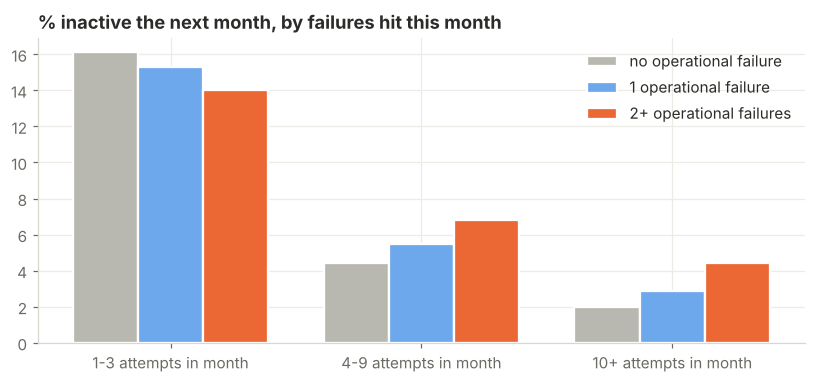

In [6]:
q = o('q28_failures_and_next_month_activity')
q['inactive_next_month_pct'] = 100 - q.active_next_month_pct
pv = q.pivot(index='activity_band', columns='operational_failures_in_month', values='inactive_next_month_pct')
fig, ax = plt.subplots(figsize=(9, 3.6)); x = np.arange(len(pv)); w = 0.26
for i, (col, colr) in enumerate(zip(pv.columns, [an.CONTEXT, '#6da7ec', an.HIGHLIGHT])):
    ax.bar(x + (i-1)*w, pv[col], w, color=colr, edgecolor='white', linewidth=1.5, label={'none': 'no operational failure', '1': '1 operational failure', '2 or more': '2+ operational failures'}[col[3:]])
ax.set_xticks(x, [b[3:] + ' in month' for b in pv.index]); ax.set_title("% inactive the next month, by failures hit this month")
ax.legend(); an.save(fig, "failures_vs_next_month_activity"); q

**Comparing like with like matters here.** Customers who hit more failures look *more* loyal overall, because busy customers both transact more and hit more failures. Within the same activity band the pattern reverses: among customers making 10+ attempts a month, those who hit two or more operational failures were about **twice as likely to be inactive the next month** (4.4% vs 2.0%). The same pattern holds for 4–9 attempts (6.8% vs 4.4%); the lightest band has too few customers with failures to say. This is an association in observational data, not proof of cause.

In [7]:
o('q27_multichannel_customers')

,channel_count,customers,txns_per_month,fees_per_month_kes,value_per_month_kes
0,1 channel,961,0.30,5.10,"1,473.00"
1,2 channels,1909,0.90,15.70,"5,358.00"
2,3+ channels,22352,5.80,153.80,"88,964.00"


In [8]:
o('q29_value_concentration')

,value_decile,customers,share_of_value_pct,share_of_fees_pct,cumulative_value_pct
0,1,2760,71.30,47.30,71.30
1,2,2760,15.10,17.10,86.40
2,3,2760,5.60,10.80,92.00
3,4,2760,3.00,7.90,95.00
4,5,2760,1.90,5.90,96.90
5,6,2759,1.30,4.30,98.20
6,7,2759,0.90,3.10,99.10
7,8,2759,0.50,2.00,99.60
8,9,2759,0.30,1.20,99.90
9,10,2759,0.10,0.40,100.00


Value is highly concentrated: the top 10% of customers move 71% of the value but pay only 47% of fees, because the heaviest value (interbank) carries a low fee per shilling.

In [9]:
o('q30_digital_adoption_by_segment')

,segment,month,active_customers,used_app_pct,used_ussd_pct
0,Mass Retail,2025-05-01,5216,56.20,66.80
1,Mass Retail,2026-10-01,7976,74.00,55.50
2,Premier,2025-05-01,912,92.50,28.60
3,Premier,2026-10-01,1549,95.50,24.60
4,SME,2025-05-01,1785,85.10,54.00
5,SME,2026-10-01,2825,89.50,47.50
6,Salaried,2025-05-01,2964,85.50,60.50
7,Salaried,2026-10-01,4868,89.80,53.40
8,Youth,2025-05-01,2989,85.90,59.80
9,Youth,2026-10-01,4227,92.10,49.20


,month,bank_volume_index,market_volume_index,bank_value_index,market_value_index
14,2026-07-01,162.20,102.40,169.30,102.20
15,2026-08-01,166.30,105.40,173.60,106.70
16,2026-09-01,173.10,100.40,179.80,102.80


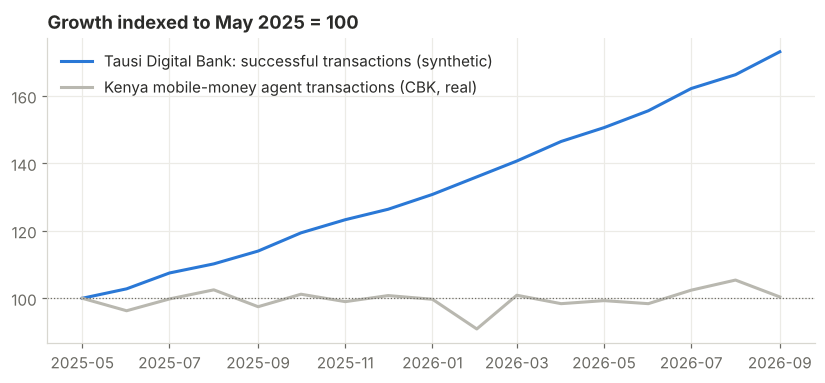

In [10]:
mk = o('q31_market_context'); mk['month'] = pd.to_datetime(mk.month)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(mk.month, mk.bank_volume_index, color=an.PRIMARY, label='Tausi Digital Bank: successful transactions (synthetic)')
ax.plot(mk.month, mk.market_volume_index, color=an.CONTEXT, label='Kenya mobile-money agent transactions (CBK, real)')
ax.axhline(100, color=an.INK_MUTED, lw=0.8, ls=':'); ax.set_title("Growth indexed to May 2025 = 100"); ax.legend(loc='upper left')
an.save(fig, "market_context_index"); mk.tail(3)

Real CBK statistics show the national mobile-money agent market roughly flat over the period, while the fictional bank's volume grew about 73% by September 2026. The comparison is context only: the two series measure different things, and the bank's figures are synthetic.